In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/sinsiter/sid-dataset/Sony_test_list.txt
/kaggle/input/datasets/sinsiter/sid-dataset/Sony_val_list.txt
/kaggle/input/datasets/sinsiter/sid-dataset/Sony_train_list.txt
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00094_00_30s.ARW
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00048_00_10s.ARW
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/10162_00_30s.ARW
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00042_00_10s.ARW
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00023_00_10s.ARW
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00095_00_30s.ARW
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00230_00_10s.ARW
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00072_00_30s.ARW
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00062_00_10s.ARW
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00196_00_10s.ARW
/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00075_00_30s.ARW
/kaggle/input/datasets/sinsite

In [1]:
!pip install rawpy
!pip install imageio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 7.2 MB/s eta 0:00:0000:0100:01


(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

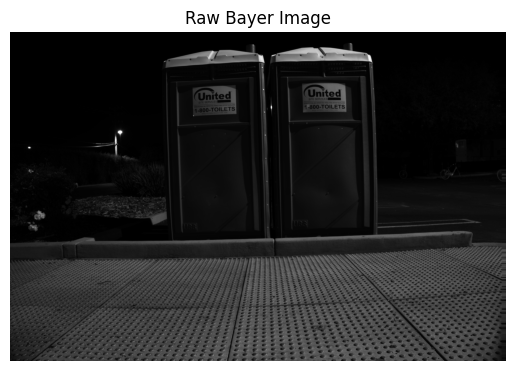

In [9]:
import rawpy
import numpy as np
import matplotlib.pyplot as plt

path = "/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00001_00_10s.ARW"

raw = rawpy.imread(path)

bayer = raw.raw_image.copy()

plt.imshow(bayer, cmap='gray')
plt.title("Raw Bayer Image")
plt.axis('off')

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

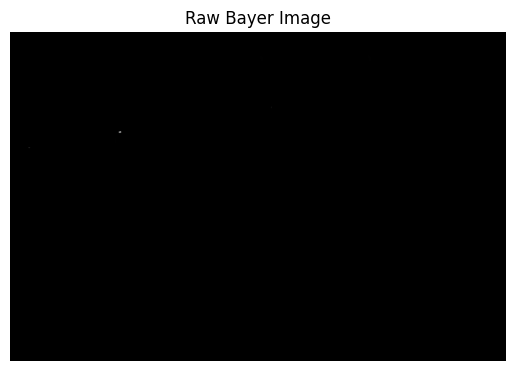

In [5]:
import rawpy
import numpy as np
import matplotlib.pyplot as plt

path = "/kaggle/input/datasets/sinsiter/sid-dataset/Sony/short/00001_00_0.04s.ARW"

raw_2 = rawpy.imread(path)

bayer = raw_2.raw_image.copy()

plt.imshow(bayer, cmap='gray')
plt.title("Raw Bayer Image")
plt.axis('off')

In [10]:
black_level = raw.black_level_per_channel
white_level = raw.white_level
pattern = raw.raw_pattern

print("Black Level:", black_level)
print("White Level:", white_level)
print("Bayer Pattern:\n", pattern)

Black Level: [512, 512, 512, 512]
White Level: 16383
Bayer Pattern:
 [[0 1]
 [3 2]]


**BLACK LEVEL CORRECTION**


In [11]:
bayer = bayer.astype(np.float32)

black = black_level[0]
bayer = bayer - black

bayer = np.clip(bayer, 0, None)
bayer = bayer / (white_level - black)

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

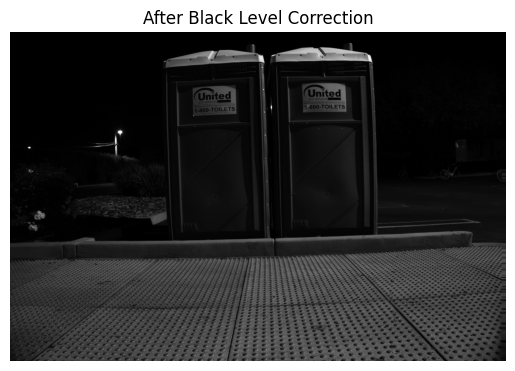

In [12]:
plt.imshow(bayer, cmap='gray')
plt.title("After Black Level Correction")
plt.axis('off')

In [13]:
R = bayer[0::2, 0::2]
G1 = bayer[0::2, 1::2]
G2 = bayer[1::2, 0::2]
B = bayer[1::2, 1::2]

G = (G1 + G2) / 2

(np.float64(-0.5), np.float64(2143.5), np.float64(1423.5), np.float64(-0.5))

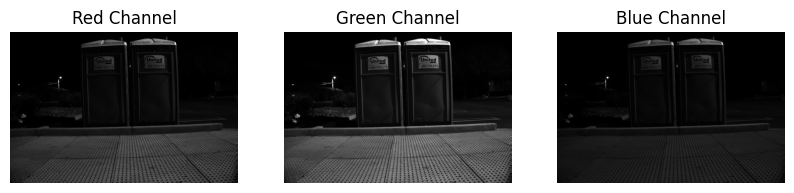

In [14]:
plt.figure(figsize=(10,5))

plt.subplot(1,3,1)
plt.imshow(R, cmap='gray')
plt.title("Red Channel")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(G, cmap='gray')
plt.title("Green Channel")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(B, cmap='gray')
plt.title("Blue Channel")
plt.axis('off')


**Stage 1:BLC → Demosaic → See imageStage**

**Stage 2:Go back → Add DPC + BNR before demosaic**



(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

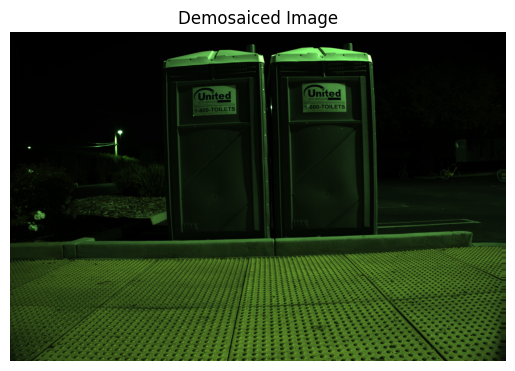

In [15]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

H, W = bayer.shape

R = np.zeros((H, W))
G = np.zeros((H, W))
B = np.zeros((H, W))

R[0::2, 0::2] = bayer[0::2, 0::2]
G[0::2, 1::2] = bayer[0::2, 1::2]
G[1::2, 0::2] = bayer[1::2, 0::2]
B[1::2, 1::2] = bayer[1::2, 1::2]

kernel_G = np.array([[0,1,0],
                     [1,4,1],
                     [0,1,0]]) / 4

kernel_RB = np.array([[1,2,1],
                      [2,4,2],
                      [1,2,1]]) / 4

R = cv2.filter2D(R, -1, kernel_RB)
G = cv2.filter2D(G, -1, kernel_G)
B = cv2.filter2D(B, -1, kernel_RB)

rgb = np.stack([R, G, B], axis=-1)
rgb = np.clip(rgb, 0, 1)

plt.imshow(rgb)
plt.title("Demosaiced Image")
plt.axis('off')

**DEFECTIVE PIXEL CORRECTION**

In [16]:
import numpy as np
import cv2

def dpc_channel(channel, threshold=0.1):
    padded = np.pad(channel, 1, mode='reflect')
    output = channel.copy()

    for i in range(channel.shape[0]):
        for j in range(channel.shape[1]):
            window = padded[i:i+3, j:j+3].flatten()
            center = window[4]
            neighbors = np.delete(window, 4)

            median = np.median(neighbors)

            if abs(center - median) > threshold:
                output[i, j] = median

    return output

In [17]:
R = bayer[0::2, 0::2]
G1 = bayer[0::2, 1::2]
G2 = bayer[1::2, 0::2]
B = bayer[1::2, 1::2]

R = dpc_channel(R)
G1 = dpc_channel(G1)
G2 = dpc_channel(G2)
B = dpc_channel(B)

In [18]:
bayer_dpc = np.zeros_like(bayer)

bayer_dpc[0::2, 0::2] = R
bayer_dpc[0::2, 1::2] = G1
bayer_dpc[1::2, 0::2] = G2
bayer_dpc[1::2, 1::2] = B

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

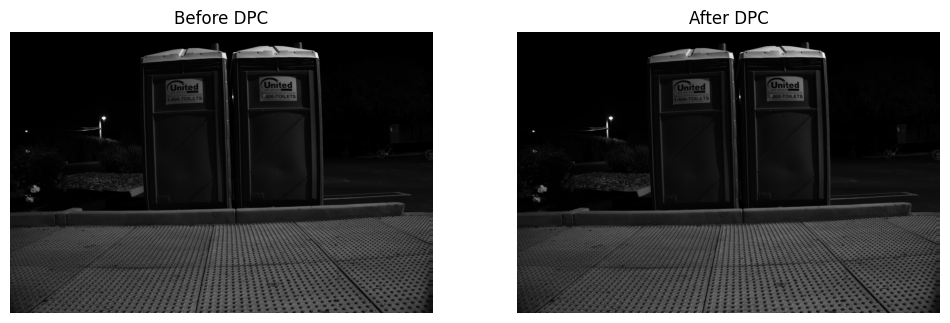

In [19]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(bayer, cmap='gray', vmin=0, vmax=1)
plt.title("Before DPC")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(bayer_dpc, cmap='gray', vmin=0, vmax=1)
plt.title("After DPC")
plt.axis('off')

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

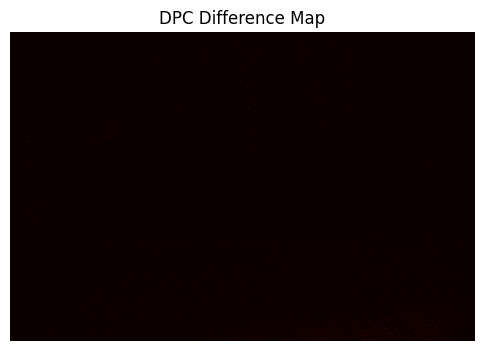

In [20]:
diff = np.abs(bayer - bayer_dpc)

plt.figure(figsize=(6,5))
plt.imshow(diff, cmap='hot')
plt.title("DPC Difference Map")
plt.axis('off')

In [21]:
print("Total pixels:", bayer.size)
print("Changed pixels:", np.sum(diff > 0))

Total pixels: 12212224
Changed pixels: 39389


In [22]:
import cv2

def bnr_channel(channel):
    return cv2.bilateralFilter(channel.astype(np.float32), d=5, sigmaColor=0.1, sigmaSpace=5)

In [23]:
R = bayer_dpc[0::2, 0::2]
G1 = bayer_dpc[0::2, 1::2]
G2 = bayer_dpc[1::2, 0::2]
B = bayer_dpc[1::2, 1::2]

R = bnr_channel(R)
G1 = bnr_channel(G1)
G2 = bnr_channel(G2)
B = bnr_channel(B)

In [24]:
bayer_bnr = np.zeros_like(bayer_dpc)

bayer_bnr[0::2, 0::2] = R
bayer_bnr[0::2, 1::2] = G1
bayer_bnr[1::2, 0::2] = G2
bayer_bnr[1::2, 1::2] = B

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

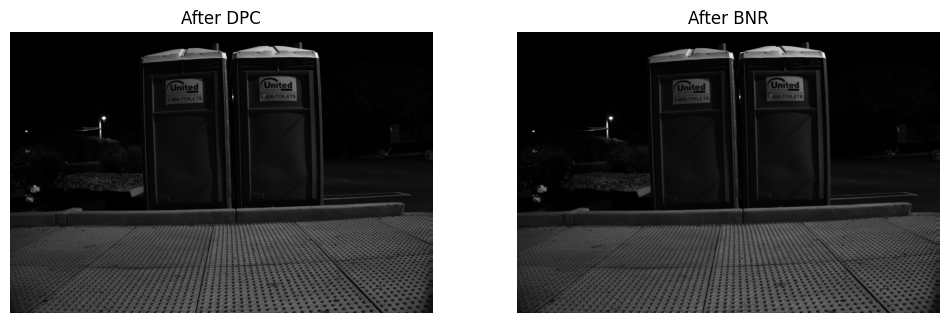

In [25]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(bayer_dpc, cmap='gray', vmin=0, vmax=1)
plt.title("After DPC")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(bayer_bnr, cmap='gray', vmin=0, vmax=1)
plt.title("After BNR")
plt.axis('off')

In [26]:
# replace input
bayer_input = bayer_bnr


(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

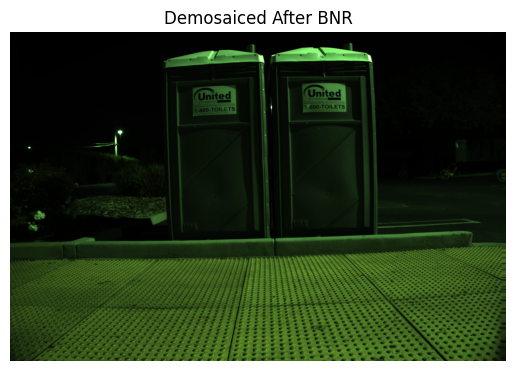

In [27]:
H, W = bayer_input.shape

R = np.zeros((H, W))
G = np.zeros((H, W))
B = np.zeros((H, W))

R[0::2, 0::2] = bayer_input[0::2, 0::2]
G[0::2, 1::2] = bayer_input[0::2, 1::2]
G[1::2, 0::2] = bayer_input[1::2, 0::2]
B[1::2, 1::2] = bayer_input[1::2, 1::2]

kernel_G = np.array([[0,1,0],
                     [1,4,1],
                     [0,1,0]]) / 4

kernel_RB = np.array([[1,2,1],
                      [2,4,2],
                      [1,2,1]]) / 4

R = cv2.filter2D(R, -1, kernel_RB)
G = cv2.filter2D(G, -1, kernel_G)
B = cv2.filter2D(B, -1, kernel_RB)

rgb_bnr = np.stack([R, G, B], axis=-1)
rgb_bnr = np.clip(rgb_bnr, 0, 1)

plt.imshow(rgb_bnr)
plt.title("Demosaiced After BNR")
plt.axis('off')

**AUTOWHITE BALANCE**

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

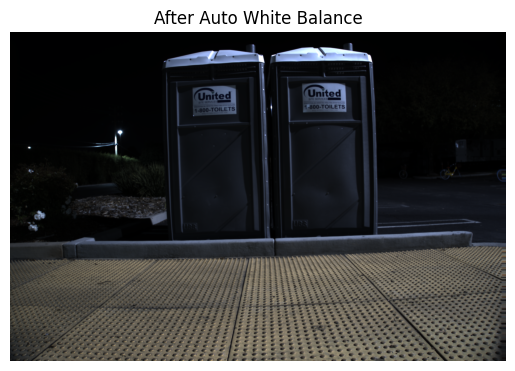

In [28]:
R = rgb_bnr[:, :, 0]
G = rgb_bnr[:, :, 1]
B = rgb_bnr[:, :, 2]

mean_R = np.mean(R)
mean_G = np.mean(G)
mean_B = np.mean(B)

gain_R = mean_G / mean_R
gain_B = mean_G / mean_B

R = R * gain_R
B = B * gain_B

rgb_awb = np.stack([R, G, B], axis=-1)
rgb_awb = np.clip(rgb_awb, 0, 1)

plt.imshow(rgb_awb)
plt.title("After Auto White Balance")
plt.axis('off')

**Bright pixel assumption**

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

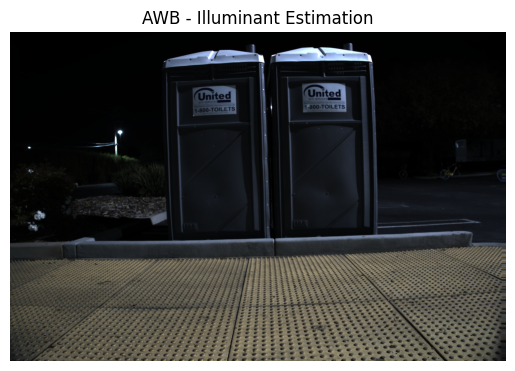

In [30]:
R = rgb_bnr[:, :, 0]
G = rgb_bnr[:, :, 1]
B = rgb_bnr[:, :, 2]

intensity = (R + G + B) / 3

threshold = np.percentile(intensity, 95)

mask = intensity >= threshold

mean_R = np.mean(R[mask])
mean_G = np.mean(G[mask])
mean_B = np.mean(B[mask])

gain_R = mean_G / mean_R
gain_B = mean_G / mean_B

R = R * gain_R
B = B * gain_B

rgb_awb_ie = np.stack([R, G, B], axis=-1)
rgb_awb_ie = np.clip(rgb_awb_ie, 0, 1)

plt.imshow(rgb_awb_ie)
plt.title("AWB - Illuminant Estimation")
plt.axis('off')

In [31]:
def estimate_illuminant_blocks(rgb, block_size=32):
    H, W, _ = rgb.shape
    
    blocks = []
    
    for i in range(0, H, block_size):
        for j in range(0, W, block_size):
            block = rgb[i:i+block_size, j:j+block_size]
            
            if block.shape[0] < block_size or block.shape[1] < block_size:
                continue
            
            mean_color = np.mean(block.reshape(-1, 3), axis=0)
            blocks.append(mean_color)
    
    blocks = np.array(blocks)
    return blocks

In [32]:
def filter_blocks(blocks, threshold=0.3):
    R = blocks[:, 0]
    G = blocks[:, 1]
    B = blocks[:, 2]
    
    rg_diff = np.abs(R - G)
    gb_diff = np.abs(G - B)
    
    mask = (rg_diff < threshold) & (gb_diff < threshold)
    
    filtered = blocks[mask]
    
    return filtered if len(filtered) > 0 else blocks

In [33]:
blocks = estimate_illuminant_blocks(rgb_bnr)
filtered_blocks = filter_blocks(blocks)

mean_R = np.mean(filtered_blocks[:, 0])
mean_G = np.mean(filtered_blocks[:, 1])
mean_B = np.mean(filtered_blocks[:, 2])

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

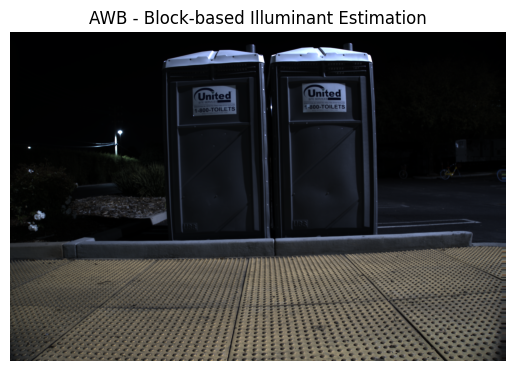

In [34]:
R = rgb_bnr[:, :, 0]
G = rgb_bnr[:, :, 1]
B = rgb_bnr[:, :, 2]

gain_R = mean_G / mean_R
gain_B = mean_G / mean_B

R = R * gain_R
B = B * gain_B

rgb_awb_pro = np.stack([R, G, B], axis=-1)
rgb_awb_pro = np.clip(rgb_awb_pro, 0, 1)

plt.imshow(rgb_awb_pro)
plt.title("AWB - Block-based Illuminant Estimation")
plt.axis('off')

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

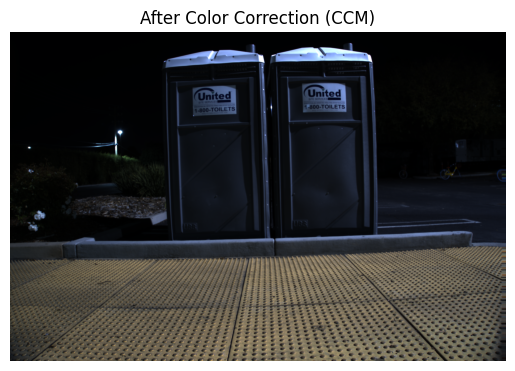

In [36]:
ccm = np.array([
    [1.3, -0.2, -0.1],
    [-0.1, 1.2, -0.1],
    [-0.1, -0.2, 1.3]
])

rgb = rgb_awb_pro.copy()

H, W, _ = rgb.shape
rgb_reshaped = rgb.reshape(-1, 3)

rgb_ccm = np.dot(rgb_reshaped, ccm.T)

rgb_ccm = rgb_ccm.reshape(H, W, 3)
rgb_ccm = np.clip(rgb_ccm, 0, 1)

plt.imshow(rgb_ccm)
plt.title("After Color Correction (CCM)")
plt.axis('off')

In [44]:
alpha = 0.1
beta = 0.05

gamma = 0.05
delta = 0.05

epsilon = 0.05
zeta = 0.1

R = rgb_awb_pro[:, :, 0]
G = rgb_awb_pro[:, :, 1]
B = rgb_awb_pro[:, :, 2]

R_corr = R - alpha * G - beta * B
G_corr = G - gamma * R - delta * B
B_corr = B - epsilon * R - zeta * G

rgb_ccm_leak = np.stack([R_corr, G_corr, B_corr], axis=-1)
rgb_ccm_leak = np.clip(rgb_ccm_leak, 0, 1)

In [45]:
intensity = np.mean(rgb_awb_pro)

In [46]:
if intensity < 0.2:
    strength = 0.3
elif intensity < 0.4:
    strength = 0.6
else:
    strength = 1.0

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

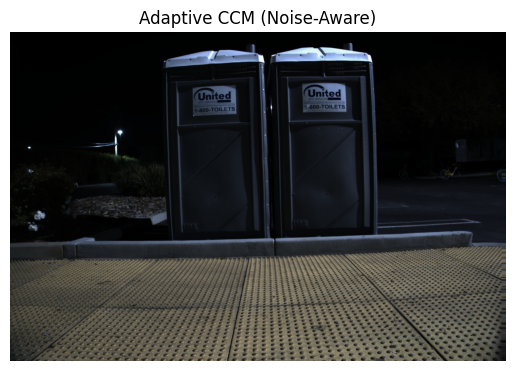

In [47]:
R_corr = R - strength * (alpha * G + beta * B)
G_corr = G - strength * (gamma * R + delta * B)
B_corr = B - strength * (epsilon * R + zeta * G)

rgb_ccm_adaptive = np.stack([R_corr, G_corr, B_corr], axis=-1)
rgb_ccm_adaptive = np.clip(rgb_ccm_adaptive, 0, 1)

plt.imshow(rgb_ccm_adaptive)
plt.title("Adaptive CCM (Noise-Aware)")
plt.axis('off')

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

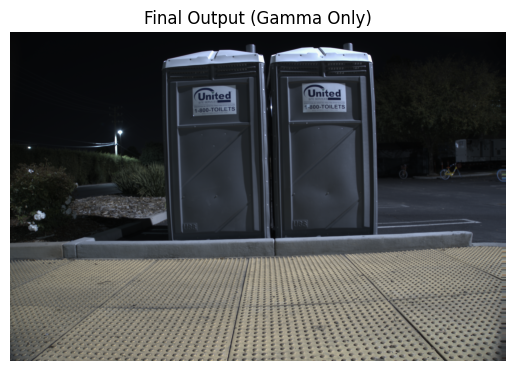

In [50]:
gamma = 1.6   # slightly lower than 1.8

rgb_final = np.power(rgb_ccm_adaptive, 1/gamma)
rgb_final = np.clip(rgb_final, 0, 1)

plt.imshow(rgb_final)
plt.title("Final Output (Gamma Only)")
plt.axis('off')

In [51]:
rgb_final = rgb_final - 0.05
rgb_final = np.clip(rgb_final, 0, 1)

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

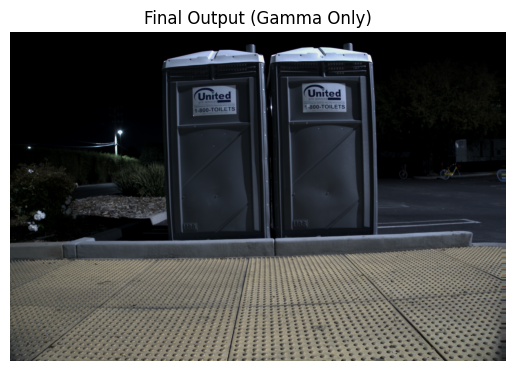

In [52]:
plt.imshow(rgb_final)
plt.title("Final Output (Gamma Only)")
plt.axis('off')

In [53]:
kernel = np.array([[0,-1,0],
                   [-1,5,-1],
                   [0,-1,0]])

rgb_sharp = cv2.filter2D(rgb_final, -1, kernel)

In [54]:
rgb_sat = rgb_final * 1.05
rgb_sat = np.clip(rgb_sat, 0, 1)

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

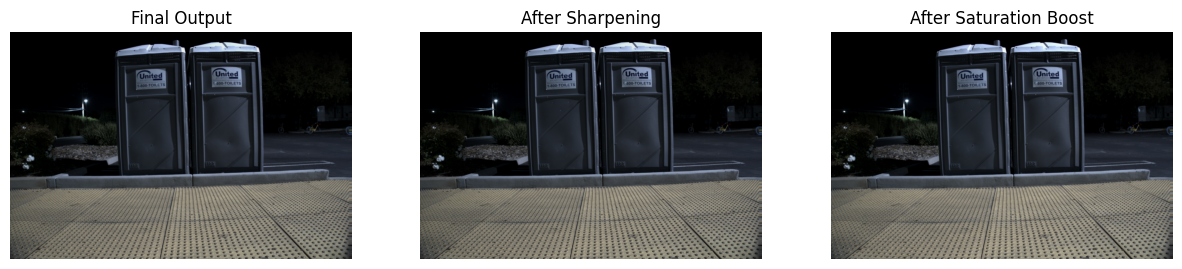

In [55]:
kernel = np.array([[0,-1,0],
                   [-1,5,-1],
                   [0,-1,0]])

rgb_sharp = cv2.filter2D(rgb_final, -1, kernel)
rgb_sharp = np.clip(rgb_sharp, 0, 1)

rgb_sat = rgb_final * 1.05
rgb_sat = np.clip(rgb_sat, 0, 1)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(rgb_final)
plt.title("Final Output")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(rgb_sharp)
plt.title("After Sharpening")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(rgb_sat)
plt.title("After Saturation Boost")
plt.axis('off')

(np.float64(-0.5), np.float64(4287.5), np.float64(2847.5), np.float64(-0.5))

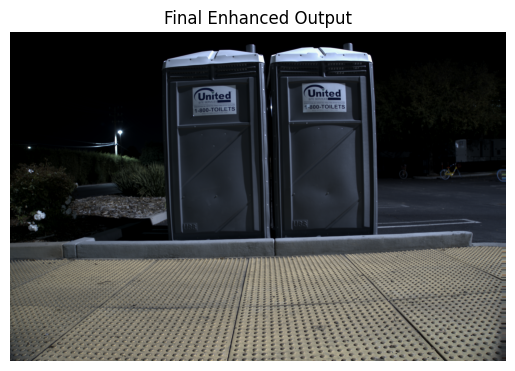

In [56]:
rgb_final_enhanced = cv2.filter2D(rgb_final, -1, kernel)
rgb_final_enhanced = rgb_final_enhanced * 1.05
rgb_final_enhanced = np.clip(rgb_final_enhanced, 0, 1)

plt.imshow(rgb_final_enhanced)
plt.title("Final Enhanced Output")
plt.axis('off')

In [57]:
plt.imsave("final_output.png", rgb_final)

In [58]:
plt.imsave("final_output_enhanced.png", rgb_final_enhanced)

In [ ]:
import rawpy
import matplotlib.pyplot as plt

path = "/kaggle/input/datasets/sinsiter/sid-dataset/Sony/long/00001_00_10s.ARW"

with rawpy.imread(path) as raw:
    rgb = raw.postprocess(
        use_camera_wb=False,
        no_auto_bright=False,
        output_bps=10
    )

plt.imshow(rgb)
plt.axis('off')
plt.show()